## Ćwiczenie 7: Operacje morfologiczne i zaawansowana segmentacja
### Część 1: Teoria – kształtowanie i naprawa struktur binarnych

### 1. Czym jest matematyczna morfologia obrazów?
Do tej pory zajmowaliśmy się filtracją w **dziedzinie jasności** – zmienialiśmy wartości pikseli (odcienie szarości), aby usunąć szum (Gauss) lub uwydatnić różnice (Sobel). 

Morfologia matematyczna to zupełnie inne podejście. Działa ona w **dziedzinie kształtu** (zbiorów). Operacje morfologiczne wykonuje się zazwyczaj na obrazach binarnych (maskach, gdzie 1 = obiekt, 0 = tło). Ich głównym zadaniem w diagnostyce medycznej jest **naprawa niedoskonałych masek** uzyskanych z algorytmów detekcji krawędzi lub progowania.

**Element strukturalny (Structuring Element):**
To mała matryca (wzorzec przestrzenny), przypominająca maskę w splotach (np. dysk, kwadrat, krzyż). Element strukturalny przesuwa się po obrazie piksel po pikselu, badając lokalne sąsiedztwo i decydując, czy dany piksel maski ma zostać "zapalony" (1) czy "zgaszony" (0).

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


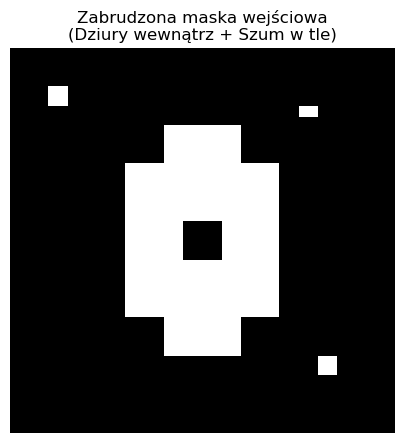

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import morphology

# --- Przygotowanie syntetycznego obrazu medycznego (np. zarys kości z defektami) ---
image = np.zeros((100, 100), dtype=bool)

# Tworzymy główny obiekt (np. fragment tkanki/kości)
image[30:70, 30:70] = True
image[20:80, 40:60] = True

# Symulujemy błędy segmentacji (typowe w obrazach medycznych):
# 1. Dziury wewnątrz narządu (False Negatives)
image[45:55, 45:55] = False  

# 2. Drobny szum w tle (False Positives)
image[10:15, 10:15] = True
image[80:85, 80:85] = True
image[15:18, 75:80] = True

# Definiujemy element strukturalny (okrągły 'próbnik' o promieniu 3 pikseli)
selem = morphology.disk(3)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap='gray')
plt.title('Zabrudzona maska wejściowa\n(Dziury wewnątrz + Szum w tle)')
plt.axis('off')
plt.show()

### 2. Operacje Fundamentalne: Erozja i Dylatacja

Pojęcia bazowe morfologii to **erozja** i **dylatacja**. 

*   **Dylatacja (Dilation - Rozrastanie):** Jeśli *przynajmniej jeden* piksel obrazu pokrywający się z elementem strukturalnym ma wartość 1, piksel centralny staje się 1. 
    *   *Efekt:* Obiekty rosną, pęknięcia zrastają się, małe dziury znikają, ale... drobny szum również rośnie.
*   **Erozja (Erosion - Kurczenie):** Tylko jeśli *wszystkie* piksele obrazu pokrywające się z elementem strukturalnym mają wartość 1, piksel centralny pozostaje 1. W przeciwnym razie staje się 0.
    *   *Efekt:* Obiekty się kurczą, drobny szum całkowicie znika (zostaje "starty"), ale... narząd staje się cieńszy, a dziury wewnątrz mogą się powiększyć.

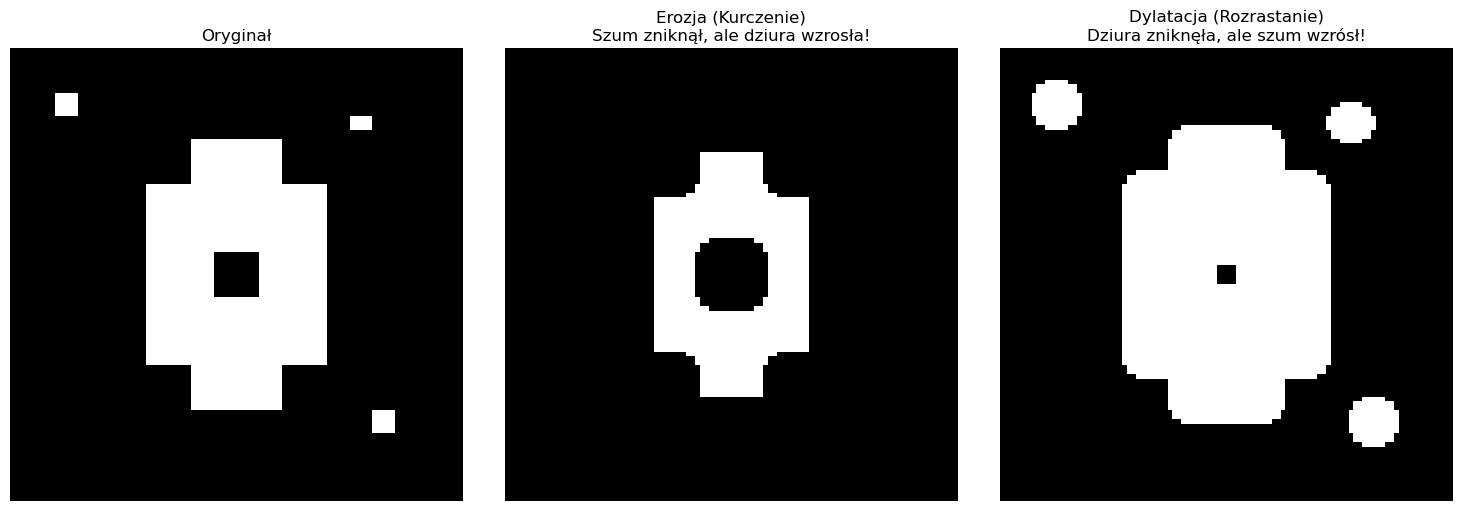

In [7]:
dilated_img = morphology.dilation(image, selem)
eroded_img = morphology.erosion(image, selem)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Oryginał')

axes[1].imshow(eroded_img, cmap='gray')
axes[1].set_title('Erozja (Kurczenie)\nSzum zniknął, ale dziura wzrosła!')

axes[2].imshow(dilated_img, cmap='gray')
axes[2].set_title('Dylatacja (Rozrastanie)\nDziura zniknęła, ale szum wzrósł!')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### 3. Operacje Złożone: Otwarcie i Zamknięcie (Złoty Standard)

Ponieważ pojedyncza erozja lub dylatacja zniekształca pole powierzchni narządu (co jest niedopuszczalne np. przy mierzeniu objętości guza w onkologii), w praktyce klinicznej stosuje się ich sekwencje:

1.  **Otwarcie (Opening):** Najpierw Erozja, potem Dylatacja. 
    *   *Logika:* Erozja niszczy drobny szum. Dylatacja odbudowuje narząd (który przetrwał erozję) do pierwotnego rozmiaru. 
    *   *Zastosowanie:* Usuwanie fałszywych wysp pikseli, odrywanie złączonych ze sobą obiektów (np. dwóch sąsiadujących krwinek).

2.  **Zamknięcie (Closing):** Najpierw Dylatacja, potem Erozja.
    *   *Logika:* Dylatacja zasypuje dziury i łączy przerwane krawędzie. Erozja przywraca pogrubiony kontur zewnętrzny do właściwych, mniejszych wymiarów.
    *   *Zastosowanie:* Łatanie ubytków w masce narządu, wygładzanie wklęsłych brzegów.

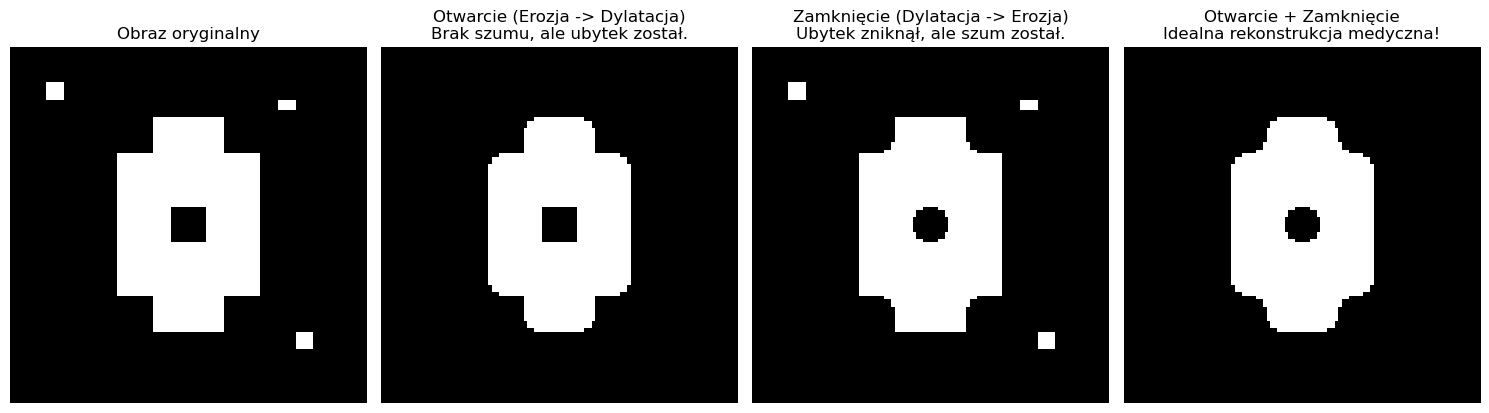

In [10]:
# Używamy tego samego elementu strukturalnego co wcześniej
opened_img = morphology.opening(image, selem)
closed_img = morphology.closing(image, selem)

# Kombinacja Otwarcie + Zamknięcie daje maskę idealną!
perfect_mask = morphology.closing(morphology.opening(image, selem), selem)

fig, axes = plt.subplots(1, 4, figsize=(15, 5))

axes[0].imshow(image, cmap='gray')
axes[0].set_title('Obraz oryginalny')

axes[1].imshow(opened_img, cmap='gray')
axes[1].set_title('Otwarcie (Erozja -> Dylatacja)\nBrak szumu, ale ubytek został.')

axes[2].imshow(closed_img, cmap='gray')
axes[2].set_title('Zamknięcie (Dylatacja -> Erozja)\nUbytek zniknął, ale szum został.')

axes[3].imshow(perfect_mask, cmap='gray')
axes[3].set_title('Otwarcie + Zamknięcie\nIdealna rekonstrukcja medyczna!')

for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Podsumowanie teoretyczne
Dzięki przemyślanemu łączeniu operacji erozji i dylatacji (Otwarcie i Zamknięcie), potrafimy przeprowadzić "chirurgię cyfrową" na masce binarnej: usunąć niedoskonałości spowodowane szumem na zdjęciu RTG czy TK, **nie zmieniając przy tym ogólnej objętości badanego narządu**. Stanowi to bezpośredni wstęp do automatycznego wyliczania wielkości struktur anatomicznych.